<a href="https://colab.research.google.com/github/unkwondriver-08/Machine-Learning-Journey/blob/main/03_Support_Vector_Machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Support Vector Machine (SVM)

## 1. What is SVM?

**SVM (Support Vector Machine)** is a supervised machine learning algorithm used for both classification and regression problems.

Its primary objective in classification is to find an optimal decision boundary (hyperplane) that separates different classes of data.

For example:
- Classifying a recipe as a Muffin or Cupcake.
- Classifying an email as Spam or Not Spam.

## 2. SVM Classification: SVC

**SVC (Support Vector Classifier)** is the classification implementation of SVM in Scikit-learn.

```python
from sklearn import svm

model = svm.SVC(kernel='linear')
```

Here:
- `svm` is the Scikit-learn module.
- `SVC` is the Support Vector Classifier.
- `kernel='linear'` specifies that we want a linear decision boundary.

### Other SVM implementations

| Model | Purpose |
|---|---|
| SVC | Classification |
| SVR | Regression |
| LinearSVC | Linear classification |

## 3. Understanding Hyperplanes

A hyperplane is a decision boundary that separates different classes.

Depending on the number of features:
- 2 features → A straight line.
- 3 features → A plane.
- More than 3 features → A hyperplane.

For a two-feature dataset, the equation of a linear decision boundary is:

\[
w_0x+w_1y+b=0
\]

Where:
- \(w_0,w_1\) = Model coefficients (weights).
- \(x,y\) = Input features.
- \(b\) = Intercept.

## 4. Understanding Maximum Margin

Multiple lines may be capable of separating two classes. However, SVM selects the decision boundary that maximizes the margin.

**Margin:** The distance between the decision boundary and the closest data points from either class.

These closest data points are called **Support Vectors**.

The important principle is:

SVM maximizes the minimum distance from the decision boundary to the closest points of either class.

In a standard hard-margin SVM:
- The margin boundaries are parallel to the decision boundary.
- The decision boundary lies midway between the two margin boundaries.
- The closest points from both classes determine the optimal boundary.

## 5. Understanding Kernel = Linear

In SVC, the kernel determines how the model constructs its decision boundary.

```python
model = svm.SVC(kernel='linear')
```

A linear kernel creates a linear decision boundary.

For example:
- 2 features → Straight line.
- 3 features → Plane.
- Higher-dimensional features → Linear hyperplane.

Other commonly used kernels include:
- `linear`
- `poly` (Polynomial)
- `rbf` (Radial Basis Function)
- `sigmoid`

## 6. Training an SVM Model

Consider the Muffin vs Cupcake classification example.

```python
import numpy as np
from sklearn import svm

# Create target labels
type_label = np.where(recipes['Type'] == 'Muffin', 0, 1)

# Select input features
ingredients = recipes[['Flour', 'Sugar']]

# Create the SVM model
model = svm.SVC(kernel='linear')

# Train the model
model.fit(ingredients, type_label)
```

### Understanding the code

**A. Creating target labels**

```python
type_label = np.where(recipes['Type'] == 'Muffin', 0, 1)
```

- Muffin is assigned label 0.
- Cupcake is assigned label 1.

Numeric encoding is convenient, but SVC can also work directly with string labels.

**B. Creating the model**

```python
model = svm.SVC(kernel='linear')
```

Creates an SVC model using a linear kernel. The model is not trained yet.

**C. Training the model**

```python
model.fit(ingredients, type_label)
```

The model learns from:
- `ingredients`: Input features (Flour and Sugar).
- `type_label`: Correct output classes (Muffin or Cupcake).

The model learns the decision boundary that best separates the two classes.

## 7. Extracting the Separating Hyperplane

After training, we can retrieve the learned coefficients and intercept.

```python
w = model.coef_[0]
```

Retrieves the coefficients (weights) of the decision boundary.

```python
model.intercept_[0]
```

Retrieves the intercept.

The equation of the decision boundary is:

\[
w_0x+w_1y+b=0
\]

Rearranging into the straight-line form:

\[
y=-\frac{w_0}{w_1}x-\frac{b}{w_1}
\]

We can calculate the slope:

```python
a = -w[0] / w[1]
```

## 8. Plotting the Separating Hyperplane

First, generate x-coordinates:

```python
xx = np.linspace(30, 60)
```

Then calculate the corresponding y-coordinates of the decision boundary:

```python
yy = a * xx - (model.intercept_[0]) / w[1]
```

Here, `xx` and `yy` provide the coordinates needed to draw the decision boundary.

## 9. Plotting the Margin Boundaries

We can draw two lines parallel to the decision boundary, passing through support vectors.

**Lower margin:**

```python
b = model.support_vectors_[0]

yy_down = a * xx + (b[1] - a * b[0])
```

**Upper margin:**

```python
b = model.support_vectors_[-1]

yy_up = a * xx + (b[1] - a * b[0])
```

Explanation:
- `model.support_vectors_` retrieves the support vectors.
- `[0]` selects the first support vector.
- `[-1]` selects the last support vector.
- Both margin lines use the same slope as the decision boundary, making them parallel.

Note: Selecting the first and last support vectors assumes they belong to opposite classes. This is not guaranteed for every dataset.

## 10. Visualizing the Decision Boundary

```python
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.lmplot(
    x='Flour',
    y='Sugar',
    data=recipes,
    hue='Type',
    palette='Set1',
    fit_reg=False,
    scatter_kws={"s": 70}
)

g.ax.plot(xx, yy, linewidth=2, color='black')
g.ax.plot(xx, yy_down, 'k--')
g.ax.plot(xx, yy_up, 'k--')

plt.show()
```

The graph displays:
- Colored scattered points: Original Muffin and Cupcake data.
- Solid black line: Decision boundary.
- Dashed black lines: Margin boundaries.

**Important:** `sns.lmplot()` creates its own figure and axes. Using `g.ax.plot()` ensures that all SVM lines are drawn on the same axes as the scatter plot.

## 11. SVM Prediction

After training, we can predict the class of a new recipe.

```python
model.predict([[100, 20]])
```

The model predicts whether the new recipe belongs to class 0 (Muffin) or class 1 (Cupcake).

---

## Quick Revision

| Concept | Meaning |
|---|---|
| SVM | Support Vector Machine |
| SVC | Support Vector Classifier |
| SVR | Support Vector Regression |
| Kernel | Defines the mathematical approach used to construct the decision boundary |
| Linear kernel | Creates a linear decision boundary |
| Hyperplane | Decision boundary separating classes |
| Support Vectors | Closest training points to the decision boundary |
| Margin | Distance from the decision boundary to the closest points |
| `fit()` | Trains the model |
| `predict()` | Predicts the class of new observations |
| `coef_` | Retrieves learned coefficients |
| `intercept_` | Retrieves the intercept |
| `support_vectors_` | Retrieves support vectors |

**Core takeaway:** SVM finds a decision boundary that maximizes the margin between classes, using the support vectors to determine the optimal boundary.

In [ ]:
import numpy as np
import pandas as pd

from sklearn import svm

#visual your data
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(font_scale = 1.2)

%matplotlib inline

#import data

recipes = pd.read_csv('recipes_muffins_cupcakes.csv')
recipes.head()

,Type,Flour,Milk,Sugar,Butter,Egg,Baking Powder,Vanilla,Salt
0,Muffin,55,28,3,7,5,2,0,0
1,Muffin,47,24,12,6,9,1,0,0
2,Muffin,47,23,18,6,4,1,0,0
3,Muffin,45,11,17,17,8,1,0,0
4,Muffin,50,25,12,6,5,2,1,0


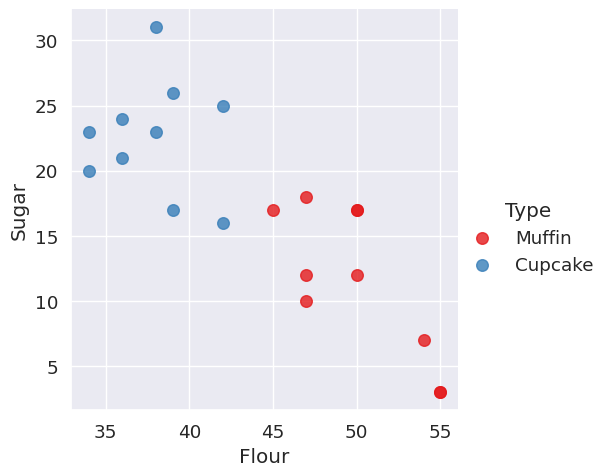

In [ ]:
# Plot our data
sns.lmplot(
    x='Flour',
    y='Sugar',
    data=recipes,
    hue='Type',
    palette='Set1',
    fit_reg=False,
    scatter_kws={"s": 70}
)

In [ ]:
#format or pre- process our data
type_label = np.where(recipes['Type']=='Muffin',0,1)
recipe_features = recipes.columns.values[1:].tolist()
recipe_features

['Flour', 'Milk', 'Sugar', 'Butter', 'Egg', 'Baking Powder', 'Vanilla', 'Salt']

In [ ]:
ingridents = recipes[['Flour', 'Sugar']].values
ingridents

array([[55,  3],
       [47, 12],
       [47, 18],
       [45, 17],
       [50, 12],
       [55,  3],
       [54,  7],
       [47, 10],
       [50, 17],
       [50, 17],
       [39, 26],
       [42, 16],
       [34, 20],
       [39, 17],
       [38, 23],
       [42, 25],
       [36, 21],
       [38, 31],
       [36, 24],
       [34, 23]])

In [ ]:
#fit model
model = svm.SVC(kernel='linear')
model.fit(ingridents, type_label)

SVC(kernel='linear')

In [ ]:
#GET THE SEPARTING HYPERPLANE
w = model.coef_[0]
a=-w[0]/w[1]
xx = np.linspace(30,60)
yy = a*xx - (model.intercept_[0])/w[1]

#PLOT THE parallels to the separating hyperplane that pass through the support vectors

b = model.support_vectors_[0]
yy_down = a*xx + (b[1]- a*b[0])
b = model.support_vectors_[-1]
yy_up = a*xx+ (b[1]- a*b[0])


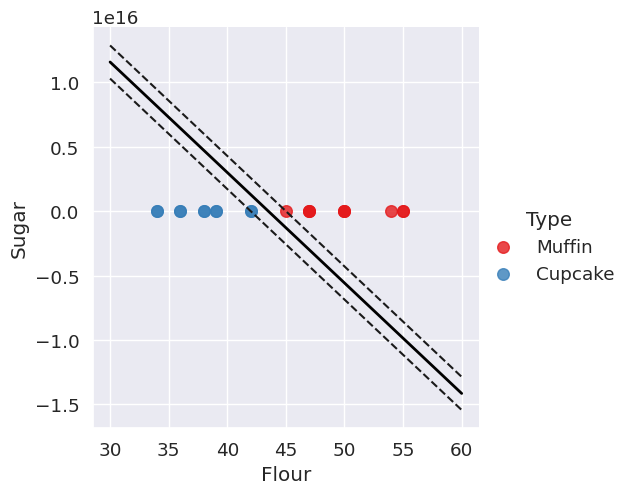

In [ ]:
# Plot our data
sns.lmplot(
    x='Flour',
    y='Sugar',
    data=recipes,
    hue='Type',
    palette='Set1',
    fit_reg=False,
    scatter_kws={"s": 70}
)
plt.plot(xx, yy, linewidth =2, color = 'black')
plt.plot(xx, yy_down, 'k--')
plt.plot(xx, yy_up, 'k--')

In [ ]:
#function for prediction  the cake

def muffin_or_cupcake(flour,sugar):
  if (model.predict([[flour,sugar]]))==0:
    print('You\'re looking at a muffin')
  else:
    print('You\'re looking at a cupcake')

In [ ]:
#calling the predict function
muffin_or_cupcake(50, 30)

You're looking at a muffin


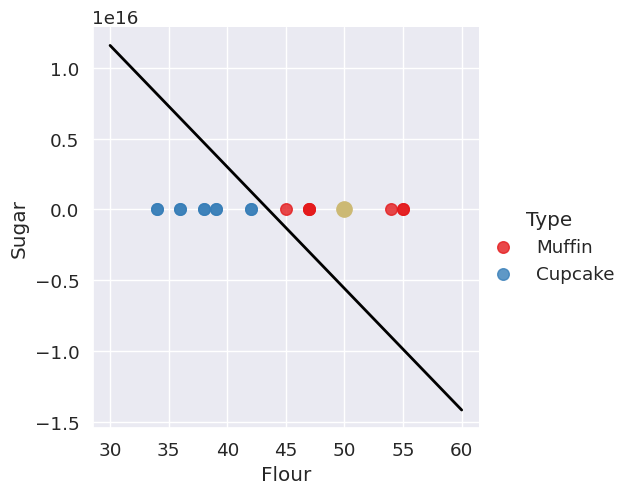

In [ ]:
#lets plot this on the graph
sns.lmplot(
    x='Flour',
    y='Sugar',
    data=recipes,
    hue='Type',
    palette='Set1',
    fit_reg=False,
    scatter_kws={"s": 70}
)
plt.plot(xx, yy, linewidth =2, color='black')
plt.plot(50, 20, 'yo', markersize = '11')